# 03 — Baseline fenotípico: modelos lineares × árvore de decisão × Random Forest × XGBoost

**Tarefa:** classificar Controle, TDAH e TEA na coorte pareada por sexo e idade (`data/processed/cohort_matched.csv`,
912 sujeitos, notebook 02).

**Features:** só o fenótipo comum às duas bases (idade, sexo, QI total, verbal, de execução e discrepância VIQ − PIQ).
Escalas clínicas (ADOS, ADI-R, ADHD index) ficam fora, porque cada uma só existe numa base e revelaria o rótulo.

**Modelos:** regressão logística (L2, C = 1) e LDA como referências lineares simples; árvore de decisão
(profundidade 3, interpretável); Random Forest e XGBoost como comitês de classificadores. Todos com classes balanceadas.

**Validação:** `GroupKFold` embaralhado com 5 dobras agrupadas por **instituição** (a instituição de teste nunca aparece no treino),
repetido com 10 sementes. (`StratifiedGroupKFold` foi descartado: com poucas instituições ele gera a mesma divisão para qualquer semente.) Acaso para 3 classes balanceadas = acurácia balanceada de **0,33**.

Código em `src/evaluation.py`.

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from sklearn.inspection import permutation_importance
from sklearn.tree import plot_tree

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from evaluation import (CLASSES, RANDOM_STATE, confusion_table, features, make_models, repeated_group_cv, target)
from matching import dataset_bias_test

FIG = ROOT / "results" / "figures"
sns.set_theme(style="whitegrid", context="notebook")
warnings.filterwarnings("ignore", message=".*sklearn.utils.parallel.delayed.*")

d = pd.read_csv(ROOT / "data" / "processed" / "cohort_matched.csv")
X, y, sitio = features(d, "qi"), target(d), d["institution"]
print(X.shape, dict(zip(CLASSES, np.bincount(y))))
X.describe().T.round(1)

(1136, 6) {'Controle': np.int64(568), 'TDAH': np.int64(284), 'TEA': np.int64(284)}


,count,mean,std,min,25%,50%,75%,max
idade,1136.0,11.7,2.8,7.0,9.5,11.4,13.4,20.6
sexo_m,1136.0,0.8,0.4,0.0,1.0,1.0,1.0,1.0
qi_total,1053.0,109.7,15.2,41.0,100.0,109.0,120.0,153.0
qi_verbal,865.0,110.9,16.3,42.0,99.0,111.0,122.0,180.0
qi_execucao,877.0,105.7,15.7,37.0,95.0,106.0,117.0,157.0
discrep_viq_piq,855.0,4.8,15.9,-43.0,-6.0,5.0,15.0,65.0


## 0. Checagem: as features novas (VIQ, PIQ) denunciam a base?
Mesmo teste do notebook 01, agora com o conjunto de features do modelo, só entre controles.

In [2]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedGroupKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from evaluation import _imputer

ctrl = d.diagnosis == "Controle"
m = make_pipeline(_imputer(RANDOM_STATE), RandomForestClassifier(500, min_samples_leaf=5, class_weight="balanced",
                                                                 random_state=RANDOM_STATE))
s = cross_val_score(m, X[ctrl], (d.dataset[ctrl] == "ABIDE").astype(int), groups=sitio[ctrl],
                    cv=StratifiedGroupKFold(5, shuffle=True, random_state=RANDOM_STATE), scoring="balanced_accuracy")
print(f"Prever a base entre controles com as features do modelo: {s.mean():.3f} ± {s.std():.3f} (acaso 0,50)")

Prever a base entre controles com as features do modelo: 0.505 ± 0.068 (acaso 0,50)


## 1. Desempenho com validação por sítio (10 repetições)

In [3]:
resultados, oof = {}, {}
for nome, modelo in make_models().items():
    resultados[nome], oof[nome] = repeated_group_cv(modelo, X, y, sitio, seeds=range(10))

resumo = pd.concat({n: r.drop(columns="semente").agg(["mean", "std"]).T for n, r in resultados.items()}, axis=1)
resumo.round(3)

Regressão logística           LDA        Árvore de decisão  \
                                 mean    std   mean    std              mean   
acc_balanceada                  0.378  0.012  0.378  0.010             0.396   
sens_Controle                   0.491  0.028  0.493  0.029             0.573   
sens_TDAH                       0.251  0.042  0.247  0.041             0.297   
sens_TEA                        0.392  0.020  0.394  0.019             0.319   
auc_macro_ovr                   0.559  0.008  0.558  0.008             0.566   
confusao_TEA_TDAH               0.331  0.018  0.327  0.016             0.304   

                         Random Forest        XGBoost         
                     std          mean    std    mean    std  
acc_balanceada     0.019         0.383  0.014   0.374  0.018  
sens_Controle      0.103         0.532  0.029   0.546  0.029  
sens_TDAH          0.096         0.214  0.026   0.204  0.021  
sens_TEA           0.095         0.402  0.024   0.371  0.021  
auc_macro_ovr      0.012         0.555  0.013   0.547  0.013  
confusao_TEA_TDAH  0.038         0.315  0.024   0.318  0.024

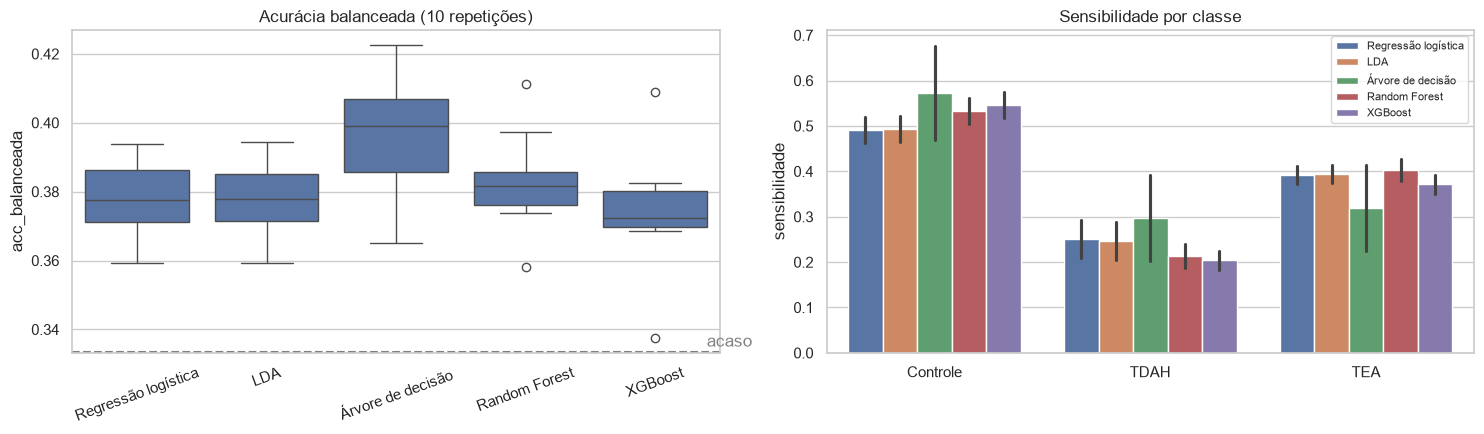

In [4]:
longo = pd.concat([r.assign(modelo=n) for n, r in resultados.items()])
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
sns.boxplot(data=longo, x="modelo", y="acc_balanceada", ax=ax[0]); ax[0].axhline(1/3, ls="--", c="gray")
ax[0].set_title("Acurácia balanceada (10 repetições)"); ax[0].set_xlabel(""); ax[0].tick_params(axis="x", rotation=20)
ax[0].text(len(resultados) - 0.6, 0.335, "acaso", color="gray")
sens = longo.melt(id_vars="modelo", value_vars=["sens_Controle", "sens_TDAH", "sens_TEA"], var_name="classe", value_name="sensibilidade")
sens["classe"] = sens["classe"].str.replace("sens_", "")
sns.barplot(data=sens, x="classe", y="sensibilidade", hue="modelo", ax=ax[1], errorbar="sd")
ax[1].set_title("Sensibilidade por classe"); ax[1].set_xlabel(""); ax[1].legend(fontsize=8)
fig.tight_layout(); fig.savefig(FIG / "03_baseline_fenotipo_metricas.png", dpi=150)

### Cada modelo × árvore: a diferença é consistente?
Diferença pareada por semente (mesmas dobras para os três modelos) e teste de Wilcoxon. Com só 10 repetições
de CV, que não são independentes, o p-valor é indicativo.

In [5]:
arv = resultados["Árvore de decisão"]
linhas = []
for nome in [n for n in resultados if n != "Árvore de decisão"]:
    for met in ["acc_balanceada", "confusao_TEA_TDAH"]:
        dif = resultados[nome][met] - arv[met]
        linhas.append({"comparação": f"{nome} − Árvore", "métrica": met, "diferença_média": dif.mean(),
                       "dp": dif.std(), "p_wilcoxon": stats.wilcoxon(dif).pvalue})
pd.DataFrame(linhas).round(3)

,comparação,métrica,diferença_média,dp,p_wilcoxon
0,Regressão logística − Árvore,acc_balanceada,-0.019,0.020,0.037
1,Regressão logística − Árvore,confusao_TEA_TDAH,0.027,0.046,0.080
2,LDA − Árvore,acc_balanceada,-0.018,0.019,0.037
3,LDA − Árvore,confusao_TEA_TDAH,0.023,0.046,0.105
4,Random Forest − Árvore,acc_balanceada,-0.014,0.026,0.154
5,Random Forest − Árvore,confusao_TEA_TDAH,0.011,0.047,0.826
6,XGBoost − Árvore,acc_balanceada,-0.023,0.028,0.027
7,XGBoost − Árvore,confusao_TEA_TDAH,0.014,0.048,0.492


## 2. Matrizes de confusão (semente 0, predições fora da dobra)

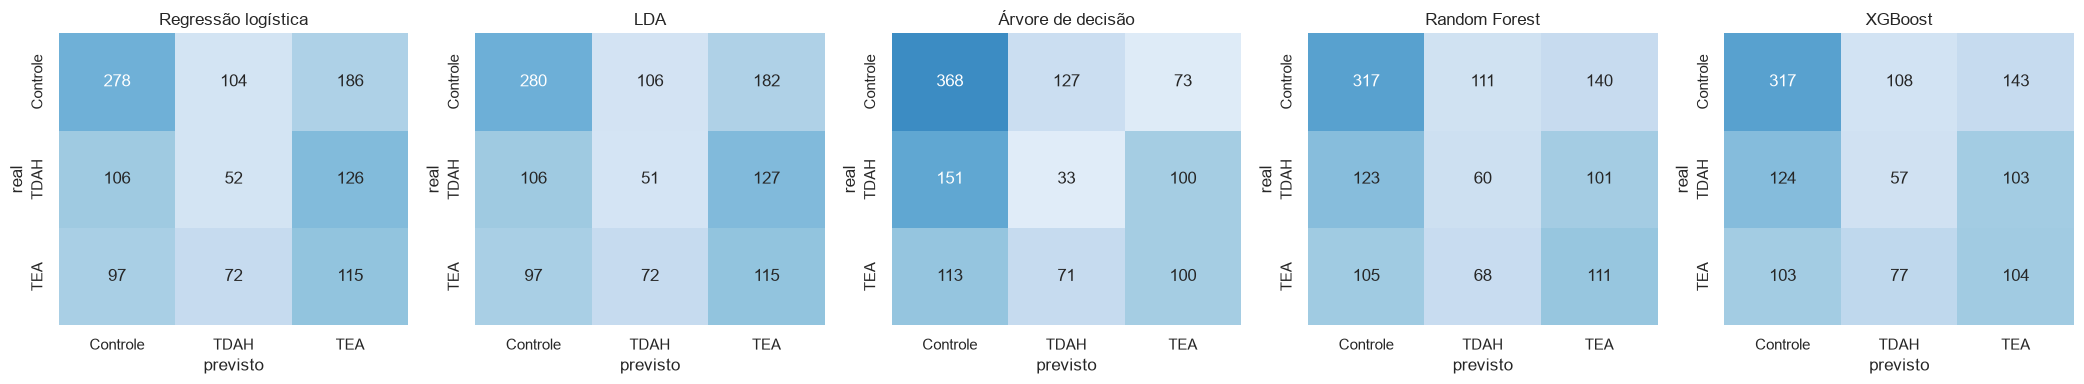

In [6]:
fig, ax = plt.subplots(1, len(oof), figsize=(4.2 * len(oof), 4))
for a, (nome, p) in zip(ax, oof.items()):
    cm = confusion_table(y, p)
    sns.heatmap(cm.div(cm.sum(axis=1), axis=0), annot=cm.values, fmt="d", cmap="Blues", vmin=0, vmax=1, cbar=False, ax=a,
                xticklabels=CLASSES, yticklabels=CLASSES)
    a.set_title(nome); a.set_xlabel("previsto"); a.set_ylabel("real")
fig.tight_layout(); fig.savefig(FIG / "03_baseline_fenotipo_confusao.png", dpi=150)

## 3. A árvore interpretável
Árvore de profundidade 3 treinada com todos os dados, para mostrar os pontos de corte. O desempenho dela é o da seção 1, não o de treino.

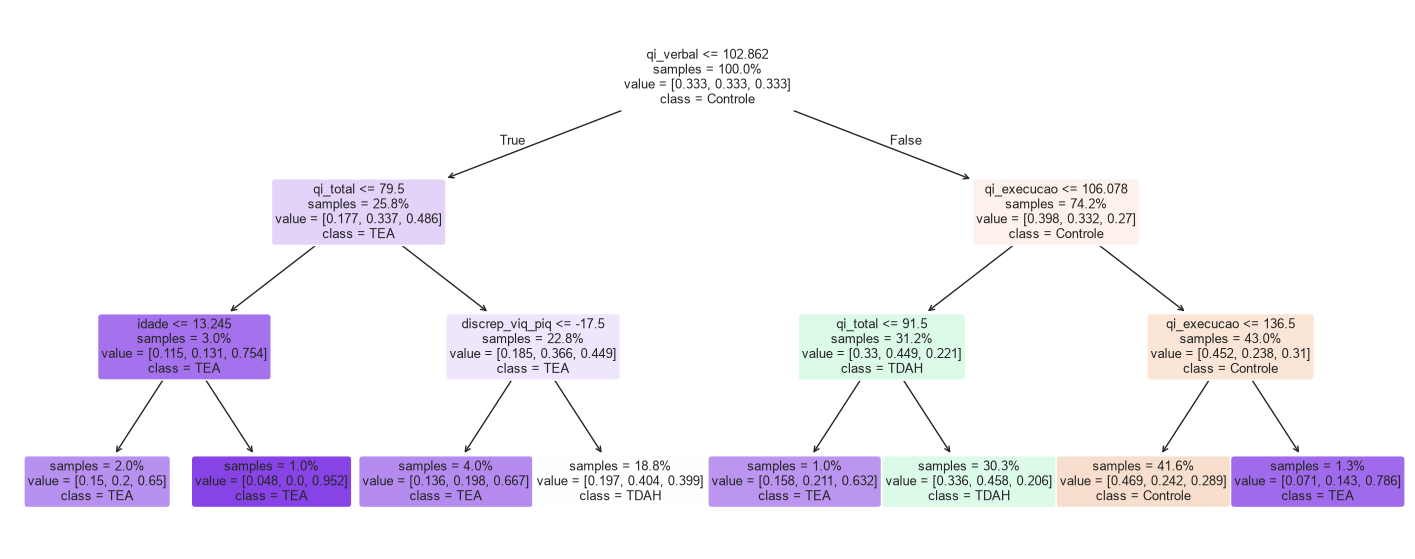

In [7]:
arvore = make_models()["Árvore de decisão"].fit(X, y)
fig, ax = plt.subplots(figsize=(18, 7))
plot_tree(arvore[-1], feature_names=X.columns, class_names=CLASSES, filled=True, rounded=True, impurity=False,
          proportion=True, fontsize=9, ax=ax)
fig.savefig(FIG / "03_arvore_fenotipo.png", dpi=150, bbox_inches="tight")

### Sensibilidade à profundidade da árvore

In [8]:
prof = []
for depth in [1, 2, 3, 4, 5, 6, 8]:
    r, _ = repeated_group_cv(make_models(tree_depth=depth)["Árvore de decisão"], X, y, sitio, seeds=range(10))
    prof.append({"profundidade": depth, "acc_bal_média": r.acc_balanceada.mean(), "dp": r.acc_balanceada.std()})
pd.DataFrame(prof).round(3)

,profundidade,acc_bal_média,dp
0,1,0.423,0.020
1,2,0.407,0.020
2,3,0.396,0.019
3,4,0.399,0.033
4,5,0.392,0.016
5,6,0.383,0.020
6,8,0.371,0.021


## 4. Quais features o Random Forest usa?
Importância por permutação nas predições fora da dobra seria o ideal; aqui, por simplicidade, numa divisão por sítio única.

sexo_m            -0.003
idade             -0.002
qi_execucao        0.017
discrep_viq_piq    0.023
qi_verbal          0.027
qi_total           0.031
dtype: float64

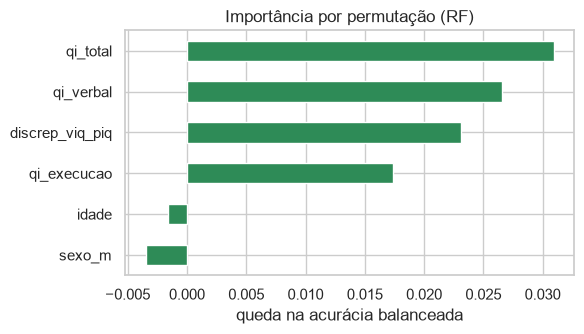

In [9]:
from sklearn.model_selection import GroupShuffleSplit
tr, te = next(GroupShuffleSplit(n_splits=1, test_size=0.3, random_state=RANDOM_STATE).split(X, y, sitio))
rf = make_models()["Random Forest"].fit(X.iloc[tr], y[tr])
pi = permutation_importance(rf, X.iloc[te], y[te], scoring="balanced_accuracy", n_repeats=30, random_state=RANDOM_STATE)
imp = pd.Series(pi.importances_mean, index=X.columns).sort_values()
ax = imp.plot.barh(color="seagreen", figsize=(6, 3.5)); ax.set_xlabel("queda na acurácia balanceada")
ax.set_title("Importância por permutação (RF)"); plt.tight_layout(); plt.savefig(FIG / "03_importancia_rf_fenotipo.png", dpi=150)
imp.round(3)

## 5. Coeficientes da regressão logística
Modelo treinado com todos os dados (features padronizadas): cada coeficiente é a variação no log-odds da classe
por 1 desvio padrão da feature. Serve para leitura, não para estimar desempenho.

,Controle,TDAH,TEA
idade,0.03,-0.01,-0.01
sexo_m,-0.01,0.01,0.01
qi_total,0.36,0.16,-0.51
qi_verbal,-0.00,-0.13,0.14
qi_execucao,-0.05,-0.21,0.26
discrep_viq_piq,0.04,0.07,-0.12


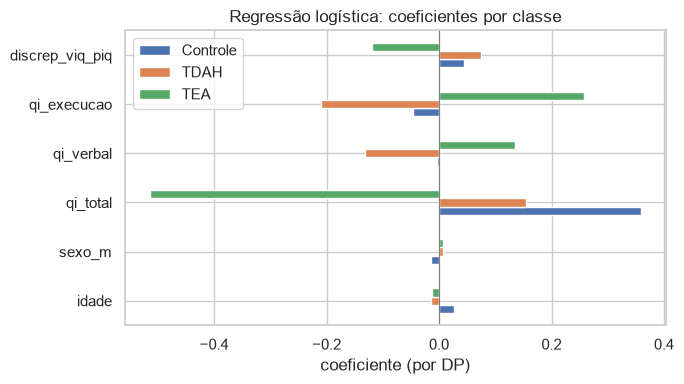

In [10]:
rl = make_models()["Regressão logística"].fit(X, y)
coef = pd.DataFrame(rl[-1].coef_, index=CLASSES, columns=X.columns).T
ax = coef.plot.barh(figsize=(7, 4), color=sns.color_palette("deep", 3)); ax.axvline(0, c="gray", lw=0.8)
ax.set_xlabel("coeficiente (por DP)"); ax.set_title("Regressão logística: coeficientes por classe")
plt.tight_layout(); plt.savefig(FIG / "03_coeficientes_logistica.png", dpi=150)
coef.round(2)

## 6. Leitura dos resultados (execução de 25/11/2026, com ABIDE II e modelos lineares)

| Modelo | Acurácia balanceada | Sens. TEA | Sens. TDAH | Sens. Controle | AUC macro |
|---|---|---|---|---|---|
| Regressão logística | 0,38 ± 0,01 | 0,39 | 0,25 | 0,49 | 0,56 |
| LDA | 0,38 ± 0,01 | 0,39 | 0,25 | 0,49 | 0,56 |
| **Árvore de decisão (prof. 3)** | **0,40 ± 0,02** | 0,32 | 0,30 | 0,57 | 0,57 |
| Random Forest | 0,38 ± 0,01 | 0,40 | 0,21 | 0,53 | 0,56 |
| XGBoost | 0,37 ± 0,02 | 0,37 | 0,20 | 0,55 | 0,55 |

Acaso = 0,33.

- **Só com fenótipo, o sinal é fraco para todos os modelos.** Nenhum passa de 0,40 de acurácia balanceada.
- **Nenhum modelo supera a árvore.** Regressão logística, LDA e XGBoost ficam ~0,02 abaixo (Wilcoxon p ≈ 0,03–0,04);
  o Random Forest fica 0,01 abaixo (p = 0,15). Com 10 repetições de CV não independentes, os p-valores são indicativos.
- **Lineares e comitês empatam (0,37–0,38).** Não há interação ou não linearidade que os comitês consigam
  aproveitar nessas features; a árvore rasa (profundidade 1: 0,42) é o que melhor generaliza.
- **TDAH é a classe mais difícil** em todos os modelos (sensibilidade 0,20–0,30); 30–33% dos casos TEA/TDAH reais
  são classificados como o outro transtorno.
- **Coeficientes da regressão logística:** QI total alto aponta controle e QI total baixo aponta TEA; dentro do
  mesmo QI total, QI de execução e verbal relativamente altos pesam para TEA. As três medidas de QI e a discrepância
  VIQ − PIQ são colineares, então os coeficientes individuais devem ser lidos com cautela.
- **A árvore tem leitura clínica:** QI verbal baixo, ou muito abaixo do de execução, aponta TEA.
- **As features do modelo não denunciam a base** (0,51 entre controles).

**Conclusão para o projeto:** o fenótipo comum às bases não basta para diferenciar TEA, TDAH e controles, e a
escolha do modelo pouco importa nesse cenário. Para testar a hipótese do canvas (comitê > árvore), são necessárias
features com mais sinal: conectividade funcional (AAL, já baixada) e as escalas clínicas do HBN (pedido de acesso).

**Limitações:** amostra majoritariamente masculina e de 7–21 anos; TEA só de bases ABIDE e TDAH só do ADHD-200;
VIQ/PIQ ausentes em ~23% (imputados); pareamento com uma única semente (42); hiperparâmetros fixos (sem busca).